# Social Media Sentiment Analysis

**Problem statement.** What drives the mood and the reach of social media posts? We look at how sentiment varies across platforms, time, countries and hashtags, and which posts get the most Likes.

**Dataset.** `sentimentdataset.csv` (Kaggle *Social Media Sentiments Analysis*): 732 posts, each with its text, a sentiment label, timestamp, user, platform, hashtags, Likes, Retweets and country.

| # | Task |
|---|---|
| 1 | Dataset exploration |
| 2 | Sentiment analysis |
| 3 | Temporal analysis |
| 4 | User engagement |
| 5 | Platform-specific analysis |
| 6 | Hashtag trends |
| 7 | Geographical trends |
| 8 | Cross-feature analysis |
| | Summary and modeling plan |

In [47]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)


def save(name):
    """Save the current figure for the slides."""
    plt.savefig(f"figures/{name}.png", dpi=120, bbox_inches="tight")

## 1. Dataset Exploration

### 1.1 Load and clean

In [48]:
df = pd.read_csv("sentimentdataset.csv")
df.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    str    
 3   Sentiment     732 non-null    str    
 4   Timestamp     732 non-null    str    
 5   User          732 non-null    str    
 6   Platform      732 non-null    str    
 7   Hashtags      732 non-null    str    
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    str    
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), str(7)
memory usage: 85.9 KB


In [50]:
# Two leftover index columns, and every text column has extra spaces ("Positive  " vs "Positive").
print("Distinct sentiment labels before cleaning:", df["Sentiment"].nunique())

df = df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])
text_cols = ["Text", "Sentiment", "User", "Platform", "Hashtags", "Country"]
df[text_cols] = df[text_cols].apply(lambda col: col.str.strip())

print("Distinct sentiment labels after cleaning: ", df["Sentiment"].nunique())
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df.describe()

Distinct sentiment labels before cleaning: 279
Distinct sentiment labels after cleaning:  191
Missing values: 0
Duplicate rows: 22


,Timestamp,Retweets,Likes,Year,Month,Day,Hour
count,732,732.000000,732.000000,732.000000,732.000000,732.000000,732.000000
mean,2020-12-08 21:37:38.196721,21.508197,42.901639,2020.471311,6.122951,15.497268,15.521858
min,2010-05-15 15:30:00,5.000000,10.000000,2010.000000,1.000000,1.000000,0.000000
25%,2019-03-08 17:27:30,17.750000,34.750000,2019.000000,3.000000,9.000000,13.000000
50%,2021-09-20 14:30:00,22.000000,43.000000,2021.000000,6.000000,15.000000,16.000000
75%,2023-02-26 11:48:45,25.000000,50.000000,2023.000000,9.000000,22.000000,19.000000
max,2023-10-22 20:45:00,40.000000,80.000000,2023.000000,12.000000,31.000000,23.000000
std,NaN,7.061286,14.089848,2.802285,3.411763,8.474553,4.113414


### 1.2 Key features

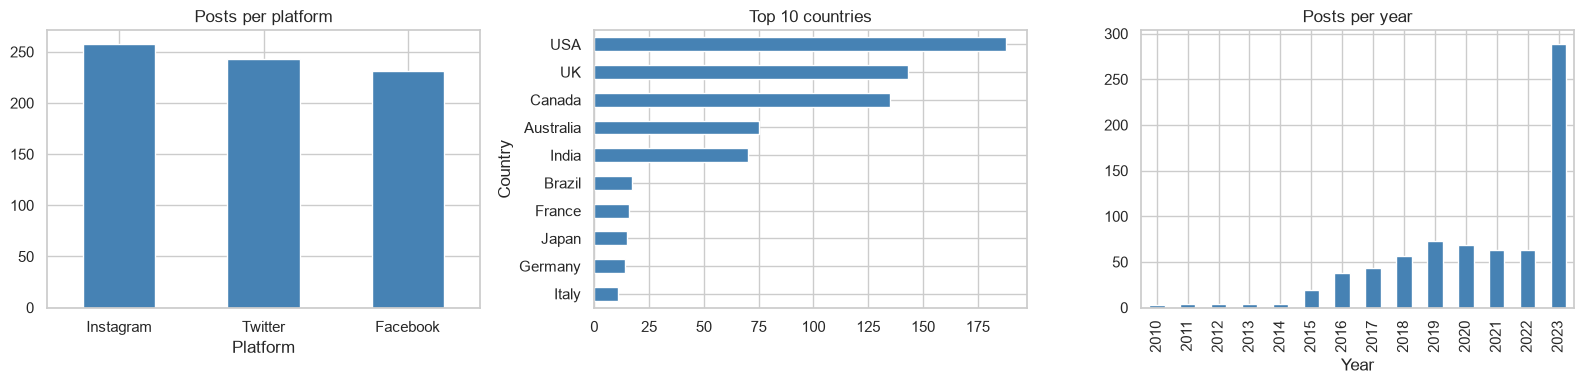

Countries: 33
Share of posts from the top 5 countries: 0.83
Share of posts from 2023: 0.39


In [51]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df["Platform"].value_counts().plot.bar(ax=axes[0], color="steelblue", rot=0, title="Posts per platform")
df["Country"].value_counts().head(10).sort_values().plot.barh(ax=axes[1], color="steelblue", title="Top 10 countries")
df["Year"].value_counts().sort_index().plot.bar(ax=axes[2], color="steelblue", title="Posts per year")

plt.tight_layout()
save("1_2_key_features")
plt.show()

print("Countries:", df["Country"].nunique())
print("Share of posts from the top 5 countries:", round(df["Country"].value_counts().head(5).sum() / len(df), 2))
print("Share of posts from 2023:", round((df["Year"] == 2023).mean(), 2))

**Observations**
- The three platforms are balanced (Instagram 258, Twitter 243, Facebook 231).
- 33 countries, but the top 5 (USA, UK, Canada, Australia, India) hold 83% of the posts.
- 2023 alone holds 39% of the posts; 2010–2014 have only 3–4 posts per year.

### 1.3 Likes and Retweets

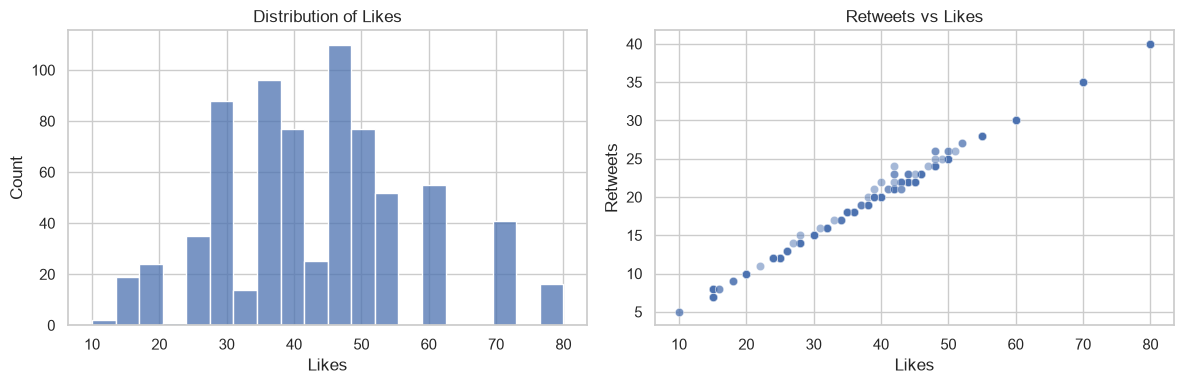

Correlation of Likes and Retweets: 0.998
Share of posts with Retweets exactly = Likes / 2: 0.59


In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["Likes"], bins=20, ax=axes[0])
axes[0].set_title("Distribution of Likes")

sns.scatterplot(data=df, x="Likes", y="Retweets", alpha=0.5, ax=axes[1])
axes[1].set_title("Retweets vs Likes")

plt.tight_layout()
save("1_3_likes_retweets")
plt.show()

print("Correlation of Likes and Retweets:", round(df["Likes"].corr(df["Retweets"]), 3))
print("Share of posts with Retweets exactly = Likes / 2:", round((df["Retweets"] == df["Likes"] / 2).mean(), 2))

**Observations**
- Likes range from 10 to 80, centred around 43.
- Retweets are almost a copy of Likes (correlation 0.998; exactly half of Likes for 59% of posts), so they add no new information. From here on, engagement = **Likes**.
- Cleaning: two leftover index columns dropped and extra spaces stripped (279 → 191 sentiment labels). No missing values; 22 duplicate rows are kept but noted.

## 2. Sentiment Analysis

### 2.1 The sentiment labels

Distinct labels: 191
Labels used only once: 79


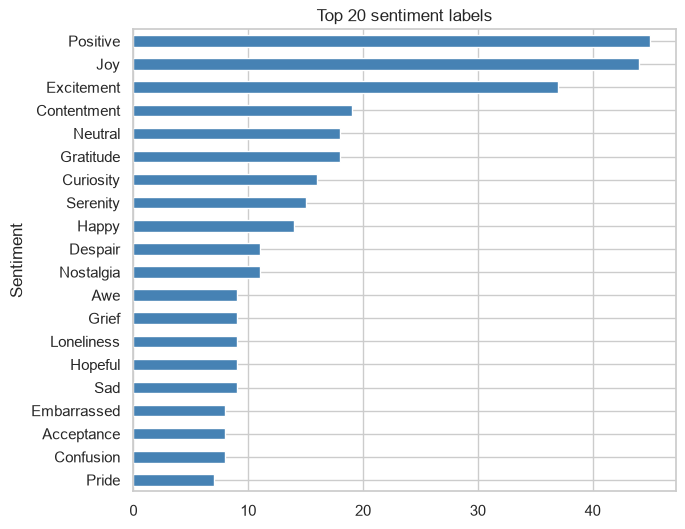

In [53]:
labels = df["Sentiment"].value_counts()
print("Distinct labels:", len(labels))
print("Labels used only once:", (labels == 1).sum())

labels.head(20).sort_values().plot.barh(figsize=(7, 6), color="steelblue", title="Top 20 sentiment labels")
save("2_1_top_labels")
plt.show()

**Observations**
- There are 191 different labels and 79 of them are used only once.
- The most common are Positive (45), Joy (44) and Excitement (37); even the top 20 labels cover less than half of the posts.

### 2.2 Grouping the labels into 4 sentiment groups

191 labels are too many to compare, so we map each label by hand to **Positive**, **Negative**, **Neutral** or **Mixed**.

Unmapped labels: <StringArray>
[]
Length: 0, dtype: str


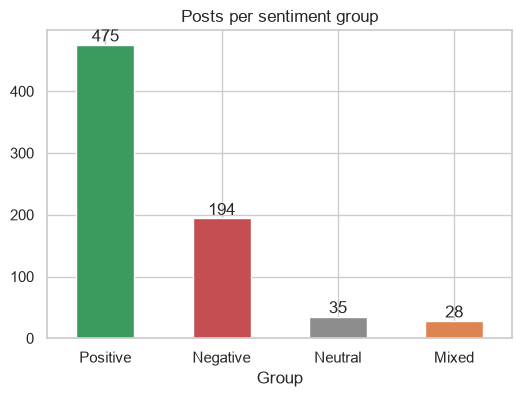

Group
Positive    0.65
Negative    0.27
Neutral     0.05
Mixed       0.04
Name: count, dtype: float64


In [54]:
POSITIVE = {
    "positive", "joy", "excitement", "contentment", "gratitude", "serenity", "happy", "awe", "hopeful",
    "acceptance", "pride", "elation", "euphoria", "enthusiasm", "determination", "playful", "inspiration",
    "happiness", "hope", "empowerment", "inspired", "admiration", "calmness", "compassion", "tenderness",
    "arousal", "fulfillment", "reverence", "proud", "grateful", "compassionate", "thrill", "enchantment",
    "love", "amusement", "kind", "empathetic", "free-spirited", "confident", "satisfaction", "accomplishment",
    "harmony", "creativity", "wonder", "adventure", "enjoyment", "affection", "adoration", "zest", "whimsy",
    "radiance", "rejuvenation", "coziness", "resilience", "tranquility", "exploration", "captivation",
    "mischievous", "overjoyed", "motivation", "joyfulreunion", "blessed", "appreciation", "confidence",
    "wonderment", "optimism", "intrigue", "playfuljoy", "mindfulness", "dreamchaser", "elegance", "melodic",
    "festivejoy", "innerjourney", "freedom", "dazzle", "adrenaline", "artisticburst", "culinaryodyssey",
    "immersion", "spark", "marvel", "positivity", "kindness", "friendship", "success", "amazement", "romance",
    "grandeur", "energy", "celebration", "charm", "ecstasy", "colorful", "hypnotic", "connection", "iconic",
    "journey", "engagement", "touched", "triumph", "heartwarming", "solace", "breakthrough", "joy in baking",
    "imagination", "vibrancy", "mesmerizing", "culinary adventure", "winter magic", "thrilling journey",
    "nature's beauty", "celestial wonder", "creative inspiration", "runway creativity", "ocean's freedom",
    "relief", "renewed effort", "curiosity", "anticipation", "sympathy",
}
NEGATIVE = {
    "despair", "grief", "loneliness", "sad", "embarrassed", "frustration", "regret", "melancholy", "hate",
    "bad", "disgust", "bitterness", "frustrated", "betrayal", "negative", "boredom", "overwhelmed",
    "desolation", "shame", "jealousy", "resentment", "fearful", "jealous", "devastated", "envious",
    "dismissive", "heartbreak", "anger", "fear", "sadness", "disappointed", "anxiety", "intimidation",
    "helplessness", "envy", "apprehensive", "isolation", "disappointment", "sorrow", "loss", "suffering",
    "emotionalstorm", "lostlove", "exhaustion", "darkness", "desperation", "ruins", "heartache", "bitter",
    "numbness", "confusion", "obstacle", "pressure", "miscalculation", "challenge",
}
NEUTRAL = {"neutral", "indifference", "contemplation", "reflection", "emotion", "pensive", "solitude", "envisioning history"}
MIXED = {"nostalgia", "ambivalence", "bittersweet", "surprise", "yearning", "suspense", "whispers of the past"}


def to_group(label):
    label = label.lower()
    if label in POSITIVE:
        return "Positive"
    if label in NEGATIVE:
        return "Negative"
    if label in NEUTRAL:
        return "Neutral"
    if label in MIXED:
        return "Mixed"
    return "Unmapped"


df["Group"] = df["Sentiment"].apply(to_group)
print("Unmapped labels:", df.loc[df["Group"] == "Unmapped", "Sentiment"].unique())

GROUPS = ["Positive", "Negative", "Neutral", "Mixed"]
COLORS = {"Positive": "#3C9A5F", "Negative": "#C44E52", "Neutral": "#8C8C8C", "Mixed": "#DD8452"}

group_counts = df["Group"].value_counts()[GROUPS]
ax = group_counts.plot.bar(color=[COLORS[g] for g in GROUPS], rot=0, title="Posts per sentiment group", figsize=(6, 4))
ax.bar_label(ax.containers[0])
save("2_2_groups")
plt.show()

print((group_counts / len(df)).round(2))

**Observations**
- After grouping: **Positive 65%**, Negative 27%, Neutral 5%, Mixed 4%.
- The data set is dominated by positive posts, so any model will need to handle the imbalance.

### 2.3 Emotional landscape per platform

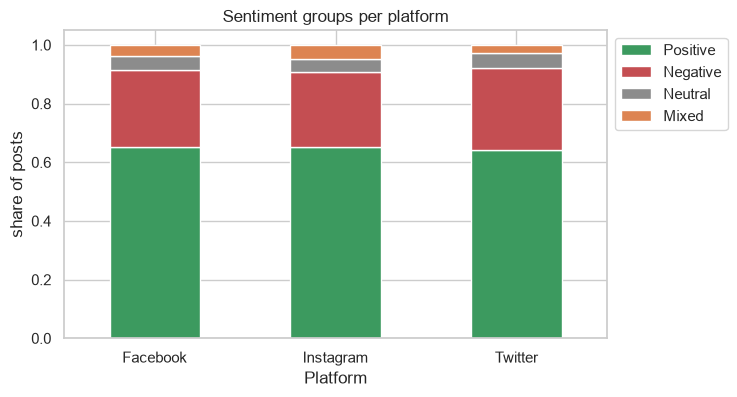

Group,Positive,Negative,Neutral,Mixed
Platform,,,,
Facebook,0.65,0.26,0.05,0.04
Instagram,0.65,0.26,0.05,0.05
Twitter,0.64,0.28,0.05,0.03


In [55]:
platform_mix = pd.crosstab(df["Platform"], df["Group"], normalize="index")[GROUPS]
platform_mix.plot.bar(stacked=True, color=COLORS, rot=0, figsize=(7, 4), title="Sentiment groups per platform")
plt.ylabel("share of posts")
plt.legend(bbox_to_anchor=(1, 1))
save("2_3_platform_groups")
plt.show()

platform_mix.round(2)

**Observations**
- The mix is almost identical on every platform (Positive 64–65%, Negative 26–28%). The emotional landscape does not depend on the platform.

## 3. Temporal Analysis

### 3.1 Over the years

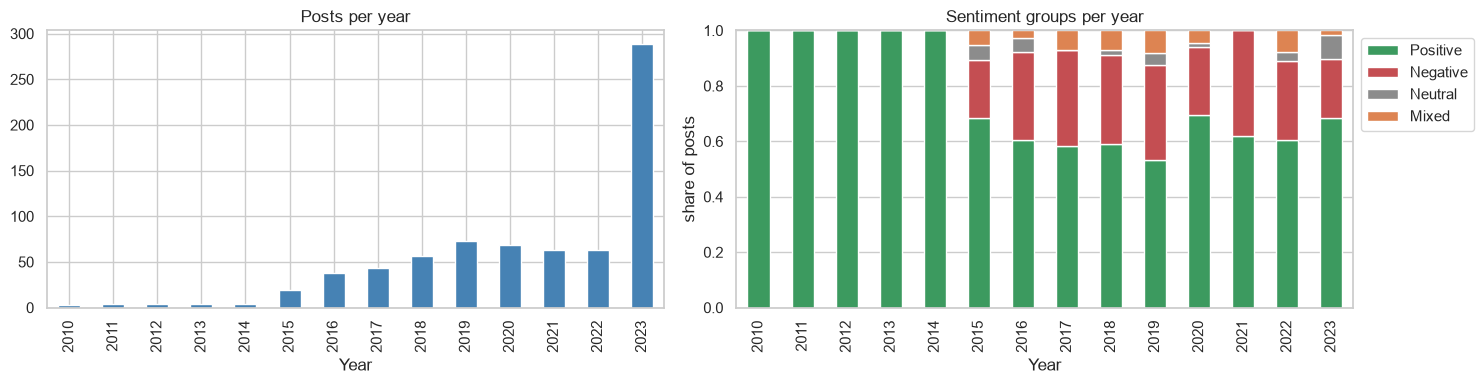

In [56]:
year_mix = pd.crosstab(df["Year"], df["Group"], normalize="index")[GROUPS]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
df["Year"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue", title="Posts per year")
year_mix.plot.bar(stacked=True, color=COLORS, ax=axes[1], title="Sentiment groups per year", legend=False)
axes[1].set_ylabel("share of posts")
axes[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
save("3_1_years")
plt.show()

**Observations**
- Posts grow over time and jump in 2023 (289 posts).
- 2010–2014 are 100% Positive, but that is only 19 posts. From 2015 on, the Positive share stays between about 53% and 70%.

### 3.2 Month, weekday and hour

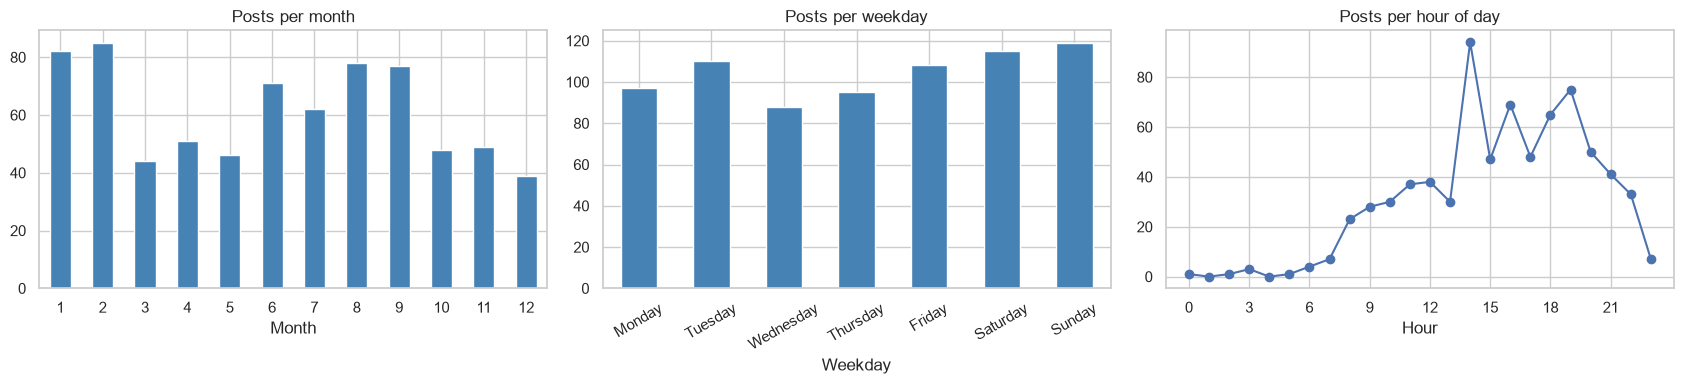

In [57]:
df["Weekday"] = df["Timestamp"].dt.day_name()
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
df["Month"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue", rot=0, title="Posts per month")
df["Weekday"].value_counts()[WEEKDAYS].plot.bar(ax=axes[1], color="steelblue", rot=30, title="Posts per weekday")
df["Hour"].value_counts().reindex(range(24), fill_value=0).plot(ax=axes[2], marker="o", title="Posts per hour of day")
axes[2].set_xticks(range(0, 24, 3))
plt.tight_layout()
save("3_2_month_weekday_hour")
plt.show()

**Observations**
- Most posts are written in the afternoon and evening (peak at 14:00); almost nothing between 0:00 and 6:00.
- Weekends are a little busier than mid-week (Sunday 119 vs Wednesday 88).
- January–February and June–September are the busiest months.

### 3.3 Is the timestamp local time?

The timestamp has no time zone. If it were UTC, countries far apart (e.g. USA and India, 10 hours apart) would post at very different recorded hours. If it is local time, they should follow the same daily rhythm.

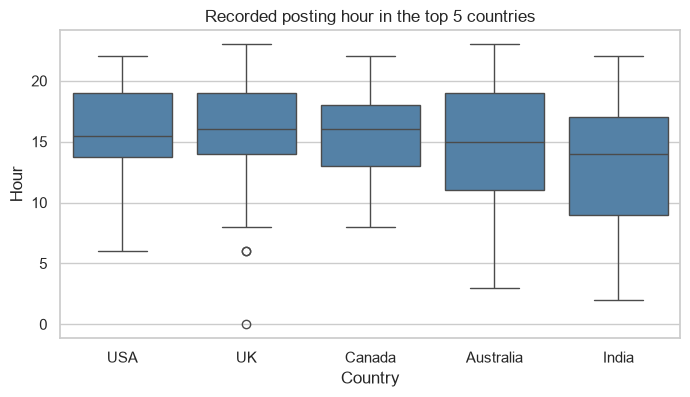

Country
Australia    14.7
Canada       15.6
India        13.4
UK           15.8
USA          15.6
Name: Hour, dtype: float64

In [58]:
top5c = df["Country"].value_counts().head(5).index
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[df["Country"].isin(top5c)], x="Country", y="Hour", order=top5c, color="steelblue")
plt.title("Recorded posting hour in the top 5 countries")
save("3_3_hour_by_country")
plt.show()

df[df["Country"].isin(top5c)].groupby("Country")["Hour"].mean().round(1)

**Observations**
- USA (UTC−5) and India (UTC+5:30) are about 10 hours apart, yet their average recorded hours are 15.6 and 13.4, and in all five countries the middle half of the posts falls between about 9:00 and 19:00. If the times were UTC, India would be shifted by about 10 hours.
- So the timestamp is the poster's **local time**, and we can read the hour directly as "time of day".

### 3.4 Sentiment by month and by time of day

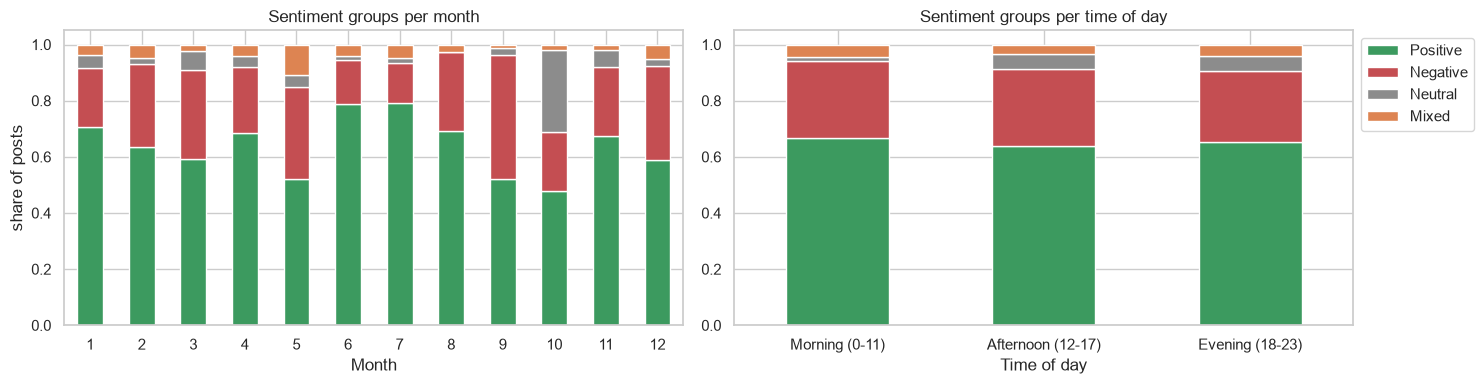

Group,Positive,Negative,Neutral,Mixed
Time of day,,,,
Morning (0-11),0.67,0.27,0.01,0.04
Afternoon (12-17),0.64,0.27,0.06,0.03
Evening (18-23),0.65,0.25,0.06,0.04


In [59]:
df["Time of day"] = pd.cut(df["Hour"], bins=[-1, 11, 17, 23], labels=["Morning (0-11)", "Afternoon (12-17)", "Evening (18-23)"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
pd.crosstab(df["Month"], df["Group"], normalize="index")[GROUPS].plot.bar(
    stacked=True, color=COLORS, rot=0, ax=axes[0], legend=False, title="Sentiment groups per month")
pd.crosstab(df["Time of day"], df["Group"], normalize="index")[GROUPS].plot.bar(
    stacked=True, color=COLORS, rot=0, ax=axes[1], title="Sentiment groups per time of day")
axes[0].set_ylabel("share of posts")
axes[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
save("3_4_month_timeofday_groups")
plt.show()

pd.crosstab(df["Time of day"], df["Group"], normalize="index")[GROUPS].round(2)

**Observations**
- Time of day hardly changes the mood (Positive 64–67% in every part of the day).
- Two months stand out: **September** is 44% Negative and **October** is 29% Neutral. Both come from 2023 (Sep 2023: 22 of 32 posts Negative; Oct 2023: 14 of 24 Neutral), so this looks like a batch of posts rather than a real season.

## 4. User Engagement Insights

Retweets are exactly half of Likes for most posts (1.3), so we measure engagement with **Likes** only.

### 4.1 Likes by sentiment

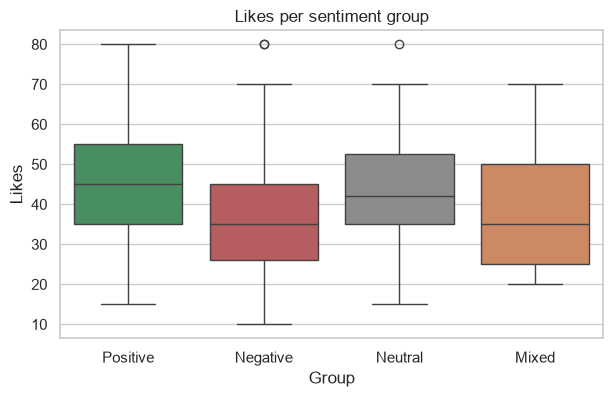

,count,mean,median
Group,,,
Positive,475,46.1,45.0
Negative,194,35.9,35.0
Neutral,35,42.2,42.0
Mixed,28,37.8,35.0


In [60]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Group", y="Likes", order=GROUPS, palette=COLORS, hue="Group", legend=False)
plt.title("Likes per sentiment group")
save("4_1_likes_by_group")
plt.show()

df.groupby("Group")["Likes"].agg(["count", "mean", "median"]).loc[GROUPS].round(1)

**Observations**
- Positive posts get the most Likes (mean 46.1) and Negative posts the fewest (35.9), a gap of about 10 Likes.

### 4.2 Likes by platform and time of day

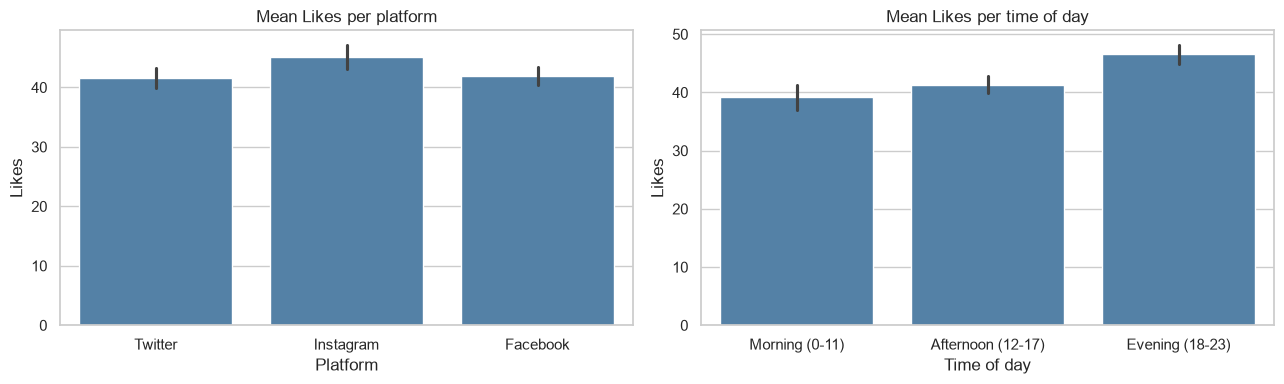

Platform
Facebook     41.9
Instagram    45.1
Twitter      41.6
Name: Likes, dtype: float64
Time of day
Morning (0-11)       39.2
Afternoon (12-17)    41.4
Evening (18-23)      46.6
Name: Likes, dtype: float64


In [61]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=df, x="Platform", y="Likes", ax=axes[0], color="steelblue")
axes[0].set_title("Mean Likes per platform")
sns.barplot(data=df, x="Time of day", y="Likes", ax=axes[1], color="steelblue")
axes[1].set_title("Mean Likes per time of day")
plt.tight_layout()
save("4_2_likes_platform_time")
plt.show()

print(df.groupby("Platform")["Likes"].mean().round(1))
print(df.groupby("Time of day", observed=True)["Likes"].mean().round(1))

**Observations**
- Instagram posts get slightly more Likes (45.1 vs about 42 on Facebook and Twitter).
- Evening posts get more Likes (46.6) than morning posts (39.2).

### 4.3 Most popular posts and most active users

In [62]:
df.sort_values("Likes", ascending=False)[["Text", "Sentiment", "Platform", "Country", "Likes"]].head(10)

,Text,Sentiment,Platform,Country,Likes
481,"Surrounded by the colors of joy, a canvas pain...",Joy,Instagram,Canada,80.0
530,"Captivated by the spellbinding plot twists, th...",Excitement,Twitter,USA,80.0
382,A sense of wonder at the vastness of the cosmo...,Wonder,Instagram,South Africa,80.0
560,"In the serene beauty of a sunset, nature unfol...",Tranquility,Instagram,Canada,80.0
470,"Dancing on sunshine, each step a celebration o...",Joy,Instagram,USA,80.0
550,"After a series of defeats, the soccer team fac...",Disappointment,Twitter,Brazil,80.0
368,Elation over discovering a rare book in a quai...,Elation,Instagram,USA,80.0
540,Celebrating a historic victory in the World Cu...,Joy,Instagram,Brazil,80.0
355,Anticipation for an upcoming adventure in an e...,Anticipation,Twitter,India,80.0
570,"Underneath the city lights, the dancer express...",Mesmerizing,Twitter,USA,80.0


In [63]:
users = df.groupby("User").agg(posts=("Text", "count"), mean_likes=("Likes", "mean"))
print("Users:", len(users), "| users with more than one post:", (users["posts"] > 1).sum())
users.sort_values(["posts", "mean_likes"], ascending=False).head(10).round(1)

Users: 670 | users with more than one post: 53


,posts,mean_likes
User,,
WinterWarmth,3,56.7
Bookworm,3,55.0
ForestDreamer,3,53.3
CarnivalDreamer,3,48.0
PeakConqueror,3,46.0
NatureAdmirer,3,43.3
RainNurturer,3,42.0
WindWhisperer,3,29.3
DawnGardener,3,28.0


**Observations**
- 16 posts reach the maximum of 80 Likes; most of them are long, descriptive, positive posts (joy, wonder, excitement).
- 670 users for 732 posts: only 53 users post more than once (at most 3 times), so there are no real "influencers" in this data.

## 5. Platform-Specific Analysis

### 5.1 Most common labels on each platform

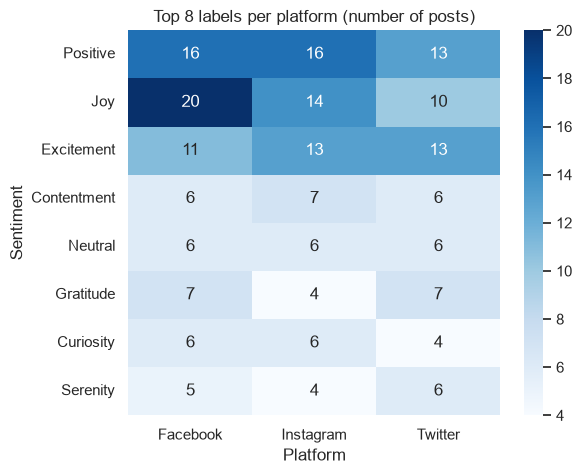

In [64]:
top_labels = df["Sentiment"].value_counts().head(8).index
label_by_platform = pd.crosstab(df["Sentiment"], df["Platform"]).loc[top_labels]

plt.figure(figsize=(6, 5))
sns.heatmap(label_by_platform, annot=True, fmt="d", cmap="Blues")
plt.title("Top 8 labels per platform (number of posts)")
save("5_1_labels_by_platform")
plt.show()

**Observations**
- The top labels are spread evenly over the platforms. The only visible difference is Joy, which is more frequent on Facebook (20) than on Twitter (10).

### 5.2 When each platform is used

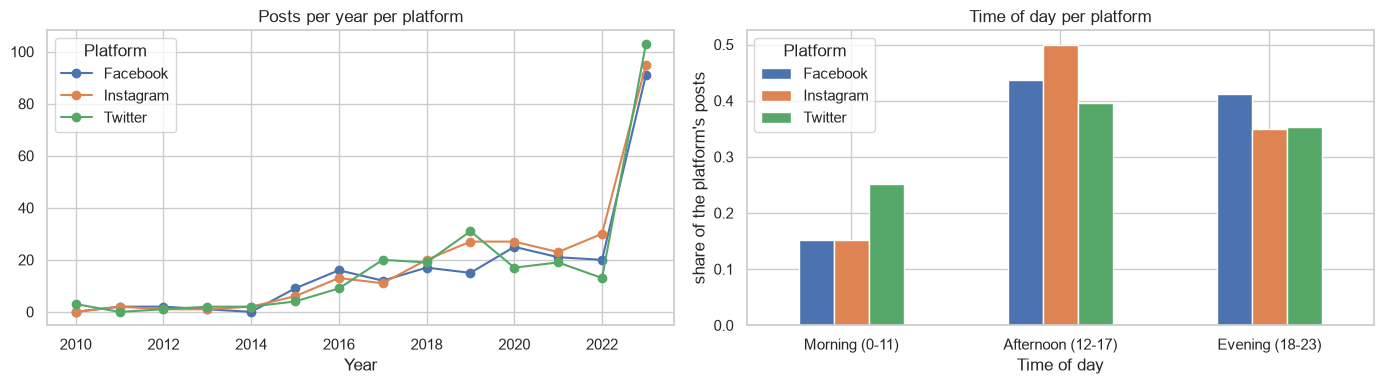

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.crosstab(df["Year"], df["Platform"]).plot(ax=axes[0], marker="o", title="Posts per year per platform")
pd.crosstab(df["Time of day"], df["Platform"], normalize="columns").plot.bar(ax=axes[1], rot=0, title="Time of day per platform")
axes[1].set_ylabel("share of the platform's posts")
plt.tight_layout()
save("5_2_platform_time")
plt.show()

**Observations**
- All three platforms grow together over the years.
- Twitter has the most morning posts (25% vs 15%); Instagram is the most afternoon-heavy (50%).

## 6. Hashtag Trends

Each post has a `Hashtags` string such as `#Nature #Park`. We split it into single hashtags.

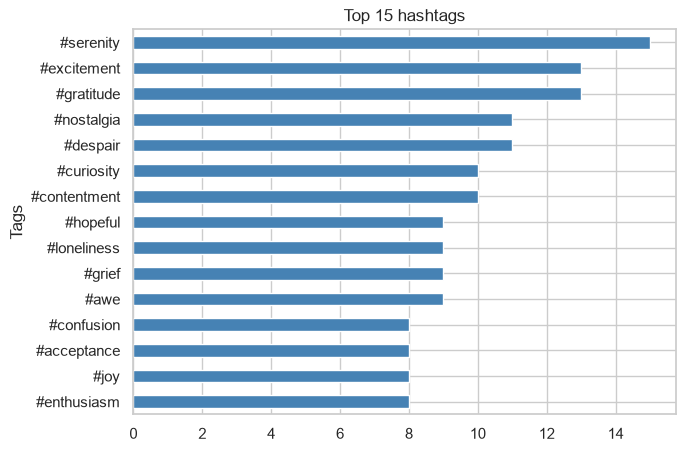

Distinct hashtags: 975
Hashtags used only once: 773


In [66]:
df["Tags"] = df["Hashtags"].str.lower().str.split()
tags = df.explode("Tags")

tags["Tags"].value_counts().head(15).sort_values().plot.barh(figsize=(7, 5), color="steelblue", title="Top 15 hashtags")
save("6_1_top_hashtags")
plt.show()

print("Distinct hashtags:", tags["Tags"].nunique())
print("Hashtags used only once:", (tags["Tags"].value_counts() == 1).sum())

In [67]:
# Is the first hashtag just the sentiment label again?
df["First tag"] = df["Tags"].str[0]
same = df["First tag"] == "#" + df["Sentiment"].str.lower().str.replace(" ", "")
print("Share of posts whose first hashtag equals the sentiment label:", round(same.mean(), 2))

Share of posts whose first hashtag equals the sentiment label: 0.71


**Observations**
- 975 different hashtags, 773 of them used only once.
- The most common hashtags (#serenity, #gratitude, #excitement, …) are the sentiment labels themselves: for 71% of posts the first hashtag equals the label.

### 6.2 Sentiment of the top hashtags

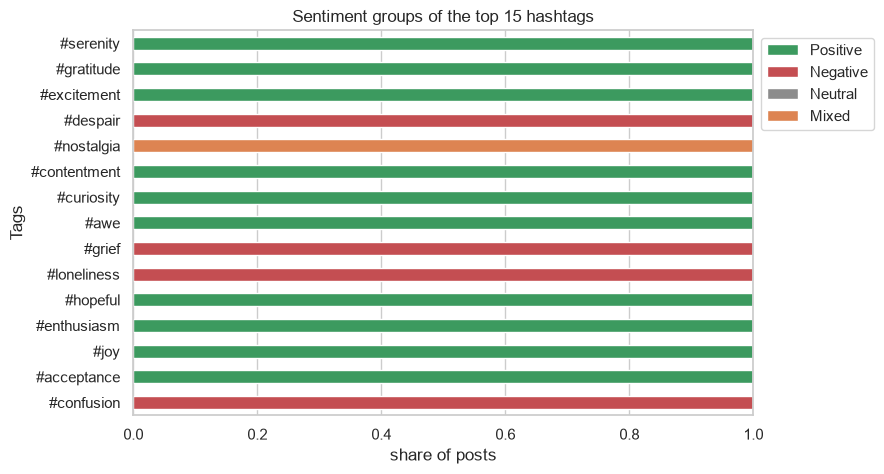

In [68]:
top_tags = tags["Tags"].value_counts().head(15).index
tag_mix = pd.crosstab(tags["Tags"], tags["Group"], normalize="index").loc[top_tags, GROUPS]
tag_mix.plot.barh(stacked=True, color=COLORS, figsize=(8, 5), title="Sentiment groups of the top 15 hashtags")
plt.gca().invert_yaxis()
plt.xlabel("share of posts")
plt.legend(bbox_to_anchor=(1, 1))
save("6_2_hashtag_groups")
plt.show()

**Observations**
- Every top hashtag belongs 100% to one sentiment group. Hashtags carry the label, so they must **not** be used as a model input (it would be cheating, i.e. data leakage).

## 7. Geographical Trends

Only the top 5 countries have more than 20 posts, so the rest are grouped as **Other**.

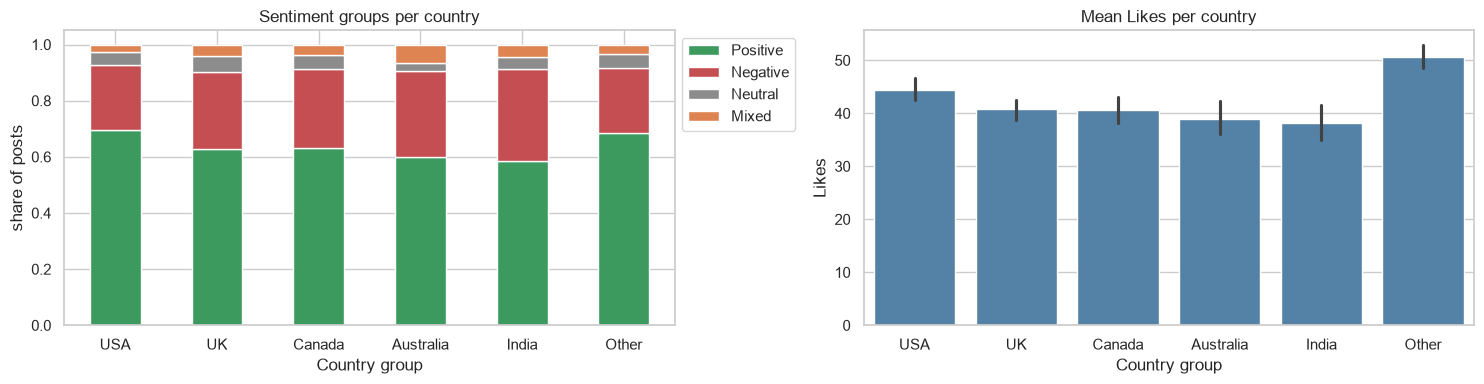

Group,Positive,Negative,Neutral,Mixed
Country group,,,,
USA,0.70,0.23,0.05,0.03
UK,0.63,0.27,0.06,0.04
Canada,0.63,0.28,0.05,0.04
Australia,0.60,0.31,0.03,0.07
India,0.59,0.33,0.04,0.04
Other,0.69,0.23,0.05,0.03


In [69]:
top5 = df["Country"].value_counts().head(5).index
df["Country group"] = df["Country"].where(df["Country"].isin(top5), "Other")
order = list(top5) + ["Other"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
pd.crosstab(df["Country group"], df["Group"], normalize="index").loc[order, GROUPS].plot.bar(
    stacked=True, color=COLORS, rot=0, ax=axes[0], title="Sentiment groups per country")
axes[0].set_ylabel("share of posts")
axes[0].legend(bbox_to_anchor=(1, 1))
sns.barplot(data=df, x="Country group", y="Likes", order=order, ax=axes[1], color="steelblue")
axes[1].set_title("Mean Likes per country")
plt.tight_layout()
save("7_1_countries")
plt.show()

pd.crosstab(df["Country group"], df["Group"], normalize="index").loc[order, GROUPS].round(2)

**Observations**
- USA has the most positive posts (70%); India (59%) and Australia (60%) the least positive, with the most Negative posts (about 31–33%).
- Mean Likes are similar in the top 5 countries (38–44); the smaller countries ("Other") get more (about 51).

## 8. Cross-Feature Analysis

### 8.1 Correlation between numeric features

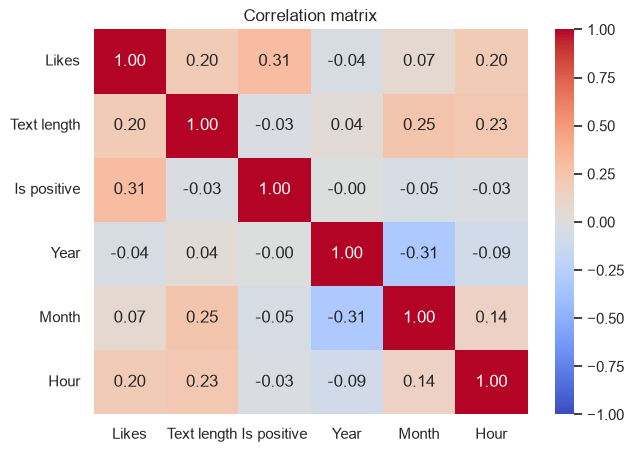

In [70]:
df["Text length"] = df["Text"].str.split().str.len()
df["Is positive"] = (df["Group"] == "Positive").astype(int)
numeric = df[["Likes", "Text length", "Is positive", "Year", "Month", "Hour"]]

plt.figure(figsize=(7, 5))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
save("8_1_correlation")
plt.show()

**Observations**
- Likes go up with a positive sentiment (0.31), longer text (0.20) and a later hour (0.20). All correlations are weak, so no single feature explains Likes.

### 8.2 Platform × country

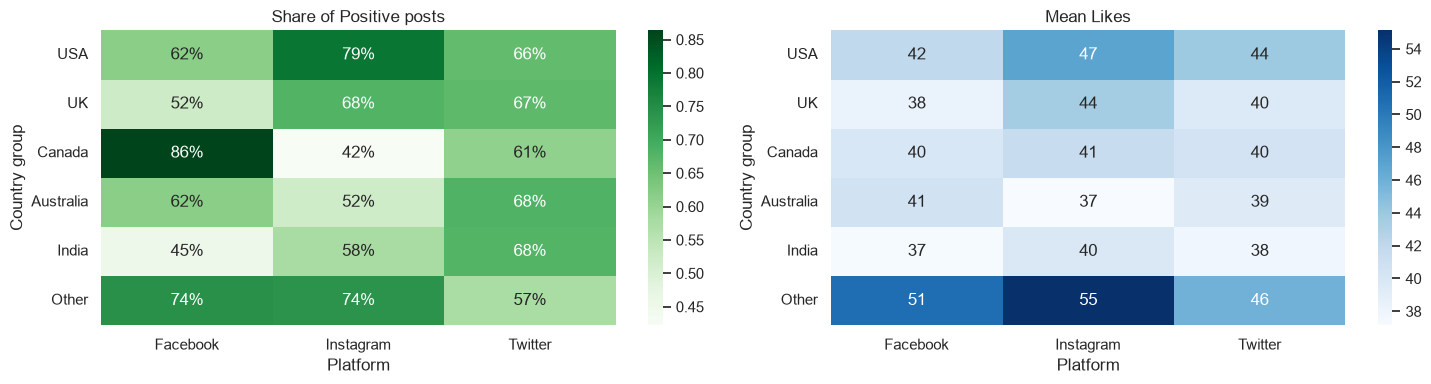

Platform,Facebook,Instagram,Twitter
Country group,,,
USA,60,72,56
UK,42,53,48
Canada,44,45,46
Australia,26,27,22
India,20,19,31
Other,39,42,40


In [71]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
positive_share = df.pivot_table(index="Country group", columns="Platform", values="Is positive", aggfunc="mean").loc[order]
sns.heatmap(positive_share, annot=True, fmt=".0%", cmap="Greens", ax=axes[0])
axes[0].set_title("Share of Positive posts")
mean_likes = df.pivot_table(index="Country group", columns="Platform", values="Likes", aggfunc="mean").loc[order]
sns.heatmap(mean_likes, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set_title("Mean Likes")
plt.tight_layout()
save("8_2_platform_country")
plt.show()

pd.crosstab(df["Country group"], df["Platform"]).loc[order]

**Observations**
- Platform and country interact: in Canada, Facebook is 86% Positive while Instagram is only 42%; in India it is the opposite trend (Facebook 45%, Twitter 68%).
- Each cell has only 19–72 posts, so these differences are hints, not firm conclusions.

## Summary

| Question | Answer |
|---|---|
| Data | 732 posts, 3 balanced platforms, 83% from 5 countries, 39% from 2023. Retweets = Likes / 2, so we use Likes. |
| Sentiment | 191 labels → 4 groups: 65% Positive, 27% Negative, 5% Neutral, 4% Mixed. Same mix on every platform. |
| Time | Timestamps are local time. People post in the afternoon/evening; mood does not change with time of day. Sep/Oct 2023 batches are unusually Negative/Neutral. |
| Engagement | Positive posts get about 10 more Likes than Negative ones; Instagram and evening posts get slightly more. |
| Hashtags | Hashtags usually repeat the sentiment label (71% of first hashtags). |
| Geography | USA is the most positive, India and Australia the least. |